# Gate 5D: compact-circuit generalization

Inference-only evaluation of all five frozen Gate 5C methods at exactly 1,000 updates, seeds 42/43/44. No training, ranking refinement, or leaderboard submission. The primary endpoints are positive-margin IOI accuracy at 0.5% and 1% nominal edge retention, separate from CPR. See the frozen protocol for the complete design.

In [1]:
from pathlib import Path
import json, subprocess, sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'src/mattr_compact_validation').exists():
    ROOT = ROOT.parent
OUT = ROOT / 'results/mattr_compact_validation/20261023_gate5d'
RUN_PREPARE = False
RUN_INFERENCE = False
RUN_REPORT = False
RUN_AUDIT = False
# Existing pinned environment only. No package installation or environment rebuild.
def run_stage(stage):
    if sys.platform == 'win32':
        cmd = ['wsl', '-d', 'Ubuntu', '--', 'bash', 'src/mattr_compact_validation/run_wsl.sh', '--stage', stage]
    else:
        cmd = ['bash', 'src/mattr_compact_validation/run_wsl.sh', '--stage', stage]
    subprocess.run(cmd, cwd=ROOT, check=True)
for flag, stage in [(RUN_PREPARE, 'prepare'), (RUN_INFERENCE, 'inference'), (RUN_REPORT, 'report'), (RUN_AUDIT, 'audit')]:
    if flag:
        run_stage(stage)
print('All expensive stages default off; saved-results analysis below.')


All expensive stages default off; saved-results analysis below.


## Frozen cohort and checkpoint identity

The official validation dataset has a `template` column; exact values are stratification labels, represented by stable hashes. Exclusions check prior development/confirmation IDs and exact clean/donor prompt hashes, and remove duplicate clean strings. Gate 1 used all 10,000 validation examples historically: this cohort is fresh relative to the smaller cohorts, not untouched by all research. Raw prompt manifests remain local.

In [2]:
protocol = json.loads((OUT / 'gate5d_protocol.json').read_text())
print('Protocol SHA-256:', (OUT / 'gate5d_protocol.sha256').read_text().strip())
display(protocol['bootstrap'])
display(protocol['criteria'])
audit = json.loads((OUT / 'cohort_audit.json').read_text())
display({k:v for k,v in audit.items() if k != 'excluded_manifests'})
display(pd.read_csv(OUT / 'official_template_labels.csv'))
display(pd.read_csv(OUT / 'checkpoint_provenance.csv'))
display(pd.read_csv(OUT / 'cohort_ids_and_hashes.csv').head())


Protocol SHA-256: ec2bf0f0a2a4fd73f4699b3040e939ae64b629d46e715cf9e531dd92c4e1ad43


{'replicates': 5000,
 'seed': 5642,
 'unit': 'prompt, shared across all methods/seeds/grid points',
 'stratification': 'resample within exact official template, fixed observed counts',
 'seed_pooling': 'equal mean across3 fixed trained seeds for each prompt; never pool3N independent rows or resample seeds',
 'primary_familywise': 'Bonferroni two endpoints: equal-tail97.5% marginal intervals (quantiles.0125,.9875) give simultaneous>=95%; per-seed intervals control2 endpoints within that seed only',
 'control_familywise': 'Bonferroni6 pooled control-endpoint contrasts (3controls*2cutoffs); descriptive per-seed contrasts',
 'secondary_auc': 'paired95% percentile interval, unadjusted and explicitly secondary'}

{'positive_mean_both_primary': True,
 'positive_seeds_each_min': 2,
 'familywise_pooled_lower_each_gt': 0.0,
 'mean_auc_delta_min': -0.02,
 'mean_compact_2_5_delta_min': -0.02,
 'invalid_masking_allowed': False,
 'structural': 'real hierarchy must additionally beat every3 control at both primary endpoints: pooled corrected lower>0 and positive in>=2 seeds each; gamma-zero equivalence prevents residual-penalty attribution',
 'classification': 'primary pass=compact-accuracy generalization; primary+allcontrols=structural advantage; positive pooled effects but failed safeguards/uncertainty=mixed/inconclusive; otherwise negative'}

{'official_rows': 10000,
 'eligible_unique_rows': 9808,
 'selected': 512,
 'selection_seed': 5542,
 'excluded_unique_prompt_hashes': 20384,
 'excluded_validation_indices': 192,
 'overlap_hashes': 0,
 'overlap_indices': 0,
 'duplicates': 0,
 'official_fingerprint': 'c93b9b8332b9b344',
 'id_fields': [],
 'ID_convention': 'official filtered validation row index; dataset exposes no separate example ID unless listed',
 'template_field': 'template',
 'template_rule': 'exact official template string; SHA256 as stable family ID, no text heuristics',
 'eligible_template_counts': {'0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4e1f74ea5092db50cea': 1219,
  '1761850092a4b3fa58baabc01960df818ec1acd216fcdc2e6484b244669c9422': 1224,
  '2a973fb4edec3c205233ae7e923a3cb5e1a1f226036229c4f36b686538ef1616': 1221,
  '4f505e7ee3bfc724786cd2d5d1dbbc632492c0b67e00957ae36ffa81b7c4b970': 1153,
  '6c714790566383068be623b67c91c9251d410916a811b1a47b2e83611bd953a5': 1173,
  '77cfacab10ad6ef85cb004f33b7264c507c800440

,template_id,official_template,cohort_prompts
0,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...,Friends {name_A} and {name_B} found a {object}...,64
1,1761850092a4b3fa58baabc01960df818ec1acd216fcdc...,When {name_A} and {name_B} were done exploring...,64
2,2a973fb4edec3c205233ae7e923a3cb5e1a1f226036229...,"Then, {name_A} and {name_B} were thinking abou...",64
3,4f505e7ee3bfc724786cd2d5d1dbbc632492c0b67e0095...,"Later, {name_A} and {name_B} met at the {place...",60
4,6c714790566383068be623b67c91c9251d410916a811b1...,"After the lunch, {name_A} and {name_B} went to...",61
5,77cfacab10ad6ef85cb004f33b7264c507c8004405a773...,While {name_A} and {name_B} relaxed at the {pl...,60
6,af843482ab88d863192825f98880df874c339b5ebf3d78...,Once {name_A} and {name_B} finished at the {pl...,60
7,d1df0b3439dc91aa88317c15aac11b38122bac7f3c3b3e...,"Afterwards, {name_A} and {name_B} went to the ...",62
8,f2c936c186d3219c4c69f340ad5942be8fecaf3f3ac9d7...,"Then, {name_A} and {name_B} had a long argumen...",17


,method,seed,step,family,gamma,shuffled,edge_count,checkpoint,checkpoint_sha256,scores,scores_sha256,config,config_sha256,training_manifest_sha256,development_manifest_sha256,model_weights_sha256
0,baseline,42,1000,bypass,0.00,False,32491,results/mattr_hierarchy/20261022_gate5c/jobs/b...,3f44b21e74b44449945ca628fca08d421ed7099507a979...,results/mattr_hierarchy/20261022_gate5c/jobs/b...,b35cffb0153771b3bd801746165f3c51bb1d06d9bd79f0...,results/mattr_hierarchy/20261022_gate5c/jobs/b...,76d730bd15ad6d57e96d9a4b388b568563f9fab7f4d9c7...,f84838fa6f1d259f5278e4b014ecf03abd5cce459a5494...,18921021f9a486e2dab0401b0170421f3512847351841d...,2e352e95c04c9ad7772afe48fb0c5d27fa3439429adca5...
1,baseline,43,1000,bypass,0.00,False,32491,results/mattr_hierarchy/20261022_gate5c/jobs/b...,70b72a6b83ff752e985c7f6206f3207cfe18b0f18a3d81...,results/mattr_hierarchy/20261022_gate5c/jobs/b...,6c8ded1f6004f0ebfd3c4ffbc1d33372753fbee61f59f3...,results/mattr_hierarchy/20261022_gate5c/jobs/b...,0bd88ce613e8382a1a6ceb070c8bc31fe38e26d7f58407...,bd354a68f4d6290ba1b11006025239827f181902b915b2...,18921021f9a486e2dab0401b0170421f3512847351841d...,2e352e95c04c9ad7772afe48fb0c5d27fa3439429adca5...
2,baseline,44,1000,bypass,0.00,False,32491,results/mattr_hierarchy/20261022_gate5c/jobs/b...,b24d1b775addd3733ae1d4de5630726033fc37926fa674...,results/mattr_hierarchy/20261022_gate5c/jobs/b...,44e84dd1f7ec944ada71bc11d3a728a3101ab31dfee256...,results/mattr_hierarchy/20261022_gate5c/jobs/b...,42ab076c3b8cd004a2e34b7760ca9da8bfad5a18b82aa9...,a54515beeae8de69a4d9a06883b8092993267fcc9038fa...,18921021f9a486e2dab0401b0170421f3512847351841d...,2e352e95c04c9ad7772afe48fb0c5d27fa3439429adca5...
3,hierarchy,42,1000,H2,0.01,False,32491,results/mattr_hierarchy/20261022_gate5c/jobs/H...,a515f5f81b112f0748bcab89e31de0fc62bb0e9946ded3...,results/mattr_hierarchy/20261022_gate5c/jobs/H...,ea19f8adfdfcf6a37630747751961c5084e9e2f664c588...,results/mattr_hierarchy/20261022_gate5c/jobs/H...,8d0a897cbce3ba4571308f1fc304104f6a0ce9528fd22f...,f84838fa6f1d259f5278e4b014ecf03abd5cce459a5494...,18921021f9a486e2dab0401b0170421f3512847351841d...,2e352e95c04c9ad7772afe48fb0c5d27fa3439429adca5...
4,hierarchy,43,1000,H2,0.01,False,32491,results/mattr_hierarchy/20261022_gate5c/jobs/H...,8457a4055f4369d86db134cb337bb5639ff9019316d7ae...,results/mattr_hierarchy/20261022_gate5c/jobs/H...,d7e123c9715b71523dc82e847e33fd346ec62021b302fa...,results/mattr_hierarchy/20261022_gate5c/jobs/H...,afc5bc72b0635352ac8f52660aa16647d37cfa2c1da94b...,bd354a68f4d6290ba1b11006025239827f181902b915b2...,18921021f9a486e2dab0401b0170421f3512847351841d...,2e352e95c04c9ad7772afe48fb0c5d27fa3439429adca5...
5,hierarchy,44,1000,H2,0.01,False,32491,results/mattr_hierarchy/20261022_gate5c/jobs/H...,6466135f6fee590c4dfd83b16fb32062ef16e9e0576cb7...,results/mattr_hierarchy/20261022_gate5c/jobs/H...,b379fb5bd58d18fa839d914008c88c1e5d598b87fb31cc...,results/mattr_hierarchy/20261022_gate5c/jobs/H...,ff0a3485607ab518dd3e80e4f858412257ff76c727974b...,a54515beeae8de69a4d9a06883b8092993267fcc9038fa...,18921021f9a486e2dab0401b0170421f3512847351841d...,2e352e95c04c9ad7772afe48fb0c5d27fa3439429adca5...
6,gamma_zero,42,1000,H2,0.00,False,32491,results/mattr_hierarchy/20261022_gate5c/jobs/H...,2e0ab0c4c7c1e706b9658aba56821ea9bd7e039cf802f7...,results/mattr_hierarchy/20261022_gate5c/jobs/H...,42a17644ff5d10258f09045a141a2c595b4526b5c31d93...,results/mattr_hierarchy/20261022_gate5c/jobs/H...,3e3acb4906708349f860e154b91eb76a75d568768c4cad...,f84838fa6f1d259f5278e4b014ecf03abd5cce459a5494...,18921021f9a486e2dab0401b0170421f3512847351841d...,2e352e95c04c9ad7772afe48fb0c5d27fa3439429adca5...
7,gamma_zero,43,1000,H2,0.00,False,32491,results/mattr_hierarchy/20261022_gate5c/jobs/H...,d43168e49d35eb359de658bc7b50137cb114bad5236cfc...,results/mattr_hierarchy/20261022_gate5c/jobs/H...,49f6203fc75d5936ee225caa629d87a9d74cb848f19697...,results/mattr_hierarchy/20261022_gate5c/jobs/H...,34f8929bbaf0168967c88a17b7afb156ea55341d5bf854...,bd354a68f4d6290ba1b1100

,example,official_filtered_index,clean_sha256,corrupted_sha256,correct_token,incorrect_token,template_id
0,0,105,c6e60f6b98eae0c4ab9cb8b6ef7e56d292d4fa1c4fabdb...,de0801424a8b5e7413ff9aa5b13f9f614ad5c301294705...,13408,3271,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...
1,1,238,4041acc7138eb17b837a00d7c8407f127741928d021595...,d99b6a6a3fb46fa97d857ff4f8086132244a6e252af2fd...,11735,6656,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...
2,2,441,ecf0687392d3d4a4a1c04798093ab51392f76e599d773c...,9cc7ff5f515ee8dfb1d8e9f6b44c52c499f1a1c258bf53...,7244,5803,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...
3,3,700,227bb73a7280830917a3f2117fc65c90ca9cd2340940e3...,3fce19986cd3cbe9bc890cd1c4c63e68b30c559306af29...,6656,10936,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...
4,4,946,e8e38cf59a46fa75ee56584aef25e133ca7b1618536d63...,ba608e36ac0e9b15f04fc1e5c9865257b08884f66cf88a...,5741,3362,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...


## Official metrics and actual circuit sizes

The original signed top-n ranking and connectivity pruning are unchanged. Nominal fractions need not equal post-pruning edge counts. CPR/CMD and accuracy log-AUC are returned by official MIB. Positive-margin accuracy is not full-vocabulary top-1; the latter is captured by the official `acc` metric from the same logits without extra forwards.

In [3]:
display(pd.read_csv(OUT / 'official_metrics.csv'))
display(pd.read_csv(OUT / 'method_means.csv'))
display(pd.read_csv(OUT / 'compact_accuracy_and_edge_counts.csv'))
display(pd.read_csv(OUT / 'faithfulness_curves.csv').head(20))


,method,seed,CPR,CMD,accuracy_log_AUC,accuracy_0.005,accuracy_0.01,accuracy_0.02,accuracy_0.05,top1_0.005,top1_0.01,top1_0.02,top1_0.05
0,baseline,42,9.717790,8.743825,0.635902,0.029297,0.130859,0.992188,1.0,0.003906,0.085938,0.990234,1.0
1,baseline,43,10.044080,9.055303,0.757503,0.316406,0.998047,1.000000,1.0,0.269531,0.998047,1.000000,1.0
2,baseline,44,9.953124,8.965233,0.739140,0.154297,1.000000,1.000000,1.0,0.091797,1.000000,1.000000,1.0
3,hierarchy,42,9.852437,8.867906,0.742325,0.382812,0.669922,1.000000,1.0,0.195312,0.408203,1.000000,1.0
4,hierarchy,43,9.897819,8.907207,0.781849,0.476562,0.998047,1.000000,1.0,0.343750,0.998047,1.000000,1.0
5,hierarchy,44,9.856788,8.863951,0.824201,0.748047,0.994141,1.000000,1.0,0.505859,0.941406,1.000000,1.0
6,gamma_zero,42,9.802341,8.817856,0.735310,0.390625,0.681641,1.000000,1.0,0.205078,0.437500,1.000000,1.0
7,gamma_zero,43,9.933279,8.942762,0.779573,0.466797,0.998047,1.000000,1.0,0.335938,0.996094,1.000000,1.0
8,gamma_zero,44,9.854069,8.861232,0.824201,0.748047,0.994141,1.000000,1.0,0.505859,0.941406,0.998047,1.0
9,shuffled,42,9.664124,8.679585,0.712952,0.181641,0.687500,0.998047,1.0,0.076172,0.527344,0.996094,1.0


,method,CPR,CMD,accuracy_log_AUC,accuracy_0.005,accuracy_0.01,accuracy_0.02,accuracy_0.05,top1_0.005,top1_0.01,top1_0.02,top1_0.05
0,baseline,9.904998,8.921454,0.710848,0.166667,0.709635,0.997396,1.0,0.121745,0.694661,0.996745,1.0
1,edge_l2,9.887741,8.904191,0.710686,0.164714,0.710286,0.997396,1.0,0.119792,0.695312,0.996745,1.0
2,gamma_zero,9.863230,8.873950,0.779695,0.535156,0.891276,1.000000,1.0,0.348958,0.791667,0.999349,1.0
3,hierarchy,9.869015,8.879688,0.782791,0.535807,0.887370,1.000000,1.0,0.348307,0.782552,1.000000,1.0
4,shuffled,9.616813,8.628152,0.752609,0.378906,0.847005,0.999349,1.0,0.271484,0.735026,0.995443,1.0


,fraction,requested_edges,actual_edges,weighted_edges,mask_sha256,nested_before_pruning,method,seed,faithfulness,accuracy,margin,top1_accuracy
0,0.005,162,92,92.0,2bfa0f46166e77ac48ff37d03386a4403b0728f70ebe72...,True,baseline,42,0.008378,0.029297,-2.809100,0.003906
1,0.010,324,273,273.0,6b8f75c8b7ecc7b3570fe7b37514e3b499bbc21ce4d558...,True,baseline,42,0.192893,0.130859,-1.696845,0.085938
2,0.020,649,638,638.0,893c903008a11f45279289f1281272ab93824dfc41847c...,True,baseline,42,7.536595,0.992188,42.571068,0.990234
3,0.050,1624,1601,1601.0,f6b8a1fcb680c911c84edc399eaadd8f096938b979874e...,True,baseline,42,12.300774,1.000000,71.289597,1.000000
4,0.005,162,118,118.0,af75c7d7378a3a8d5d63ca2a556488e065d51bf4287d93...,True,baseline,43,0.338863,0.316406,-0.816931,0.269531
5,0.010,324,309,309.0,a3ef3f6b478a610ba27eb52083903c5d5cf068975787c8...,True,baseline,43,3.824356,0.998047,20.193659,0.998047
6,0.020,649,638,638.0,38776927001bab76aa3440f20594c398cfad501dfd5787...,True,baseline,43,8.607513,1.000000,49.026573,1.000000
7,0.050,1624,1612,1612.0,ecd4b7eb32b5d3c0387ce103a34d430e0474c31c5aa3de...,True,baseline,43,12.433974,1.000000,72.092529,1.000000
8,0.005,162,116,116.0,027d80326971c65cc0af15f0bdaa53b4dce0269ca30322...,True,baseline,44,0.220560,0.154297,-1.530064,0.091797
9,0.010,324,296,296.0,d8a4c79104fffae19b936b5f1bf7ba1072ab7ff8134639...,True,baseline,44,2.827917,1.000000,14.187111,1.000000


,fraction,requested_edges,actual_edges,weighted_edges,mask_sha256,nested_before_pruning,method,seed,faithfulness,accuracy,margin,top1_accuracy
0,0.001,32,2,2.0,cf491bd6b75d14066c3d091f824e39869f691a46a80cba...,True,baseline,42,0.000944,0.027344,-2.853913,0.003906
1,0.002,64,2,2.0,cf491bd6b75d14066c3d091f824e39869f691a46a80cba...,True,baseline,42,0.000944,0.027344,-2.853913,0.003906
2,0.005,162,92,92.0,2bfa0f46166e77ac48ff37d03386a4403b0728f70ebe72...,True,baseline,42,0.008378,0.029297,-2.809100,0.003906
3,0.010,324,273,273.0,6b8f75c8b7ecc7b3570fe7b37514e3b499bbc21ce4d558...,True,baseline,42,0.192893,0.130859,-1.696845,0.085938
4,0.020,649,638,638.0,893c903008a11f45279289f1281272ab93824dfc41847c...,True,baseline,42,7.536595,0.992188,42.571068,0.990234
5,0.050,1624,1601,1601.0,f6b8a1fcb680c911c84edc399eaadd8f096938b979874e...,True,baseline,42,12.300774,1.000000,71.289597,1.000000
6,0.100,3249,3246,3246.0,74ca1a4f7e88bfc7c073d55e05887b851777f634e61b74...,True,baseline,42,12.573198,1.000000,72.931755,0.994141
7,0.200,6498,6498,6498.0,cb9341466df4aa975ef2caff5af7dd8291f45eb6280b56...,True,baseline,42,13.017443,1.000000,75.609680,1.000000
8,0.500,16245,16245,16245.0,71e4c473b14bf6b2144b7ef7337fe319fe7956c82d7e3a...,True,baseline,42,13.192665,1.000000,76.665909,0.953125
9,1.000,32491,32491,32491.0,a9f1223d410b396b359761d1b89bc6570dd9c22b9606ec...,True,baseline,42,1.000000,0.984375,3.168407,0.843750


## Shared paired prompt uncertainty and controls

Five thousand resamples are shared across methods and fixed trained seeds, within exact official templates. Two primary endpoints use Bonferroni simultaneous 95% coverage (97.5% marginal intervals). Six pooled control-endpoint contrasts form a separate family. Secondary accuracy log-AUC intervals are unadjusted. Seeds are never treated as independent prompt observations; intervals do not establish unseen-template generalization.

In [4]:
display(pd.read_csv(OUT / 'paired_bootstrap_accuracy.csv'))
display(pd.read_csv(OUT / 'paired_bootstrap_accuracy_auc.csv'))
display(pd.read_csv(OUT / 'template_family_paired_differences.csv'))
display(json.loads((OUT / 'gate5d_decision.json').read_text()))


,comparator,seed,fraction,delta,lower,upper,family_endpoints,corrected,broken,interval_scope
0,baseline,42,0.005,0.353516,0.308594,0.398438,2,181.000000,0.000000,2 cutoffs within this seed; no correction acro...
1,baseline,43,0.005,0.160156,0.118140,0.203125,2,98.000000,16.000000,2 cutoffs within this seed; no correction acro...
2,baseline,44,0.005,0.593750,0.544922,0.642578,2,304.000000,0.000000,2 cutoffs within this seed; no correction acro...
3,baseline,equal_seed_mean,0.005,0.369141,0.337891,0.400073,2,194.333333,5.333333,shared prompt draws; equally weighted FIXED seeds
4,baseline,42,0.010,0.539062,0.488281,0.587891,2,276.000000,0.000000,2 cutoffs within this seed; no correction acro...
...,...,...,...,...,...,...,...,...,...,...
59,edge_l2,equal_seed_mean,0.020,0.002604,0.000000,0.006510,6,1.333333,0.000000,shared prompt draws; equally weighted FIXED seeds
60,edge_l2,42,0.050,0.000000,0.000000,0.000000,2,0.000000,0.000000,2 cutoffs within this seed; no correction acro...
61,edge_l2,43,0.050,0.000000,0.000000,0.000000,2,0.000000,0.000000,2 cutoffs within this seed; no correction acro...
62,edge_l2,44,0.050,0.000000,0.000000,0.000000,2,0.000000,0.000000,2 cutoffs within this seed; no correction acro...


,comparator,seed,delta,lower,upper
0,baseline,42,0.106423,0.098559,0.114375
1,baseline,43,0.024346,0.019795,0.028896
2,baseline,44,0.085061,0.079600,0.090459
3,baseline,equal_seed_mean,0.071943,0.067091,0.076649
4,gamma_zero,42,0.007015,0.003697,0.010499
5,gamma_zero,43,0.002275,-0.000233,0.005006
6,gamma_zero,44,0.000000,0.000000,0.000000
7,gamma_zero,equal_seed_mean,0.003097,0.001612,0.004593
8,shuffled,42,0.029373,0.023412,0.035214
9,shuffled,43,-0.026604,-0.032166,-0.021074


,template_id,method,seed,fraction,prompts,accuracy_delta
0,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...,hierarchy,42,0.005,64,0.421875
1,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...,hierarchy,43,0.005,64,0.234375
2,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...,hierarchy,44,0.005,64,0.750000
3,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...,hierarchy,42,0.010,64,0.593750
4,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...,hierarchy,43,0.010,64,0.000000
...,...,...,...,...,...,...
427,f2c936c186d3219c4c69f340ad5942be8fecaf3f3ac9d7...,edge_l2,43,0.020,17,0.000000
428,f2c936c186d3219c4c69f340ad5942be8fecaf3f3ac9d7...,edge_l2,44,0.020,17,0.000000
429,f2c936c186d3219c4c69f340ad5942be8fecaf3f3ac9d7...,edge_l2,42,0.050,17,0.000000
430,f2c936c186d3219c4c69f340ad5942be8fecaf3f3ac9d7...,edge_l2,43,0.050,17,0.000000


{'primary': {'passed': False,
  'checks': {'valid_conventions': True,
   'positive_mean_0.005': True,
   'corrected_lower_0.005': True,
   'positive_2seeds_0.005': True,
   'positive_mean_0.01': True,
   'corrected_lower_0.01': True,
   'positive_2seeds_0.01': False,
   'accuracy_auc': True,
   'compact_2_5_safeguard': True}},
 'controls': {'gamma_zero': {'passed': False,
   'checks': {'valid_conventions': True,
    'positive_mean_0.005': True,
    'corrected_lower_0.005': False,
    'positive_2seeds_0.005': False,
    'positive_mean_0.01': False,
    'corrected_lower_0.01': False,
    'positive_2seeds_0.01': False}},
  'shuffled': {'passed': True,
   'checks': {'valid_conventions': True,
    'positive_mean_0.005': True,
    'corrected_lower_0.005': True,
    'positive_2seeds_0.005': True,
    'positive_mean_0.01': True,
    'corrected_lower_0.01': True,
    'positive_2seeds_0.01': True}},
  'edge_l2': {'passed': False,
   'checks': {'valid_conventions': True,
    'positive_mean_0.005'

## Correctness and compute

CUDA-synchronized monotonic timing counts real model root-forward calls and example-forwards. Official graph-independent reference scalars are safely reused; no mutable patched activations are cached. CUDA allocation/reservation is not total physical VRAM occupancy. All model gradients remain absent; model weight hashes are unchanged. Prior results and protocols are hash-protected.

In [5]:
for name in ['correctness_passed.json','model_weight_audit.json','inference_process_summary.json','final_validation.json']:
    display(json.loads((OUT/name).read_text()))
display(pd.read_csv(OUT / 'per_method_compute.csv'))
display(pd.read_csv(OUT / 'compute_accounting.csv'))


{'passed': True,
 'official_patcher_unchanged': True,
 'batch_repeat_singleton': True,
 'reference_cache_equivalent': True,
 'full_returns_clean': True,
 'nested_masks': True,
 'mask_audit_points': 10,
 'optimizer_updates': 0,
 'backward_calls': 0}

{'passed': True,
 'before_sha256': '2e352e95c04c9ad7772afe48fb0c5d27fa3439429adca5f63d46fc45e6469a76',
 'after_sha256': '2e352e95c04c9ad7772afe48fb0c5d27fa3439429adca5f63d46fc45e6469a76',
 'optimizer_updates': 0,
 'model_backwards': 0,
 'stored_model_gradients': False}

{'success': True,
 'seconds': 1364.913888659,
 'counts': {'forward_batches': 7950,
  'example_forwards': 155720,
  'backward_calls': 0,
  'optimizer_updates': 0},
 'reference_or_result_cache_hits': 28,
 'donor_activation_cache_hits': 0,
 'activation_cache': 'disabled; official immutable reference scalar cache enabled',
 'unique_evaluation_prompts': 512,
 'fixed_rankings': 15}

{'passed': True,
 'historical_files_unchanged': 7724,
 'evaluated_rankings': 15,
 'protocol_sha256': 'ec2bf0f0a2a4fd73f4699b3040e939ae64b629d46e715cf9e531dd92c4e1ad43',
 'cohort_size': 512,
 'actual_forwards_verified': True,
 'weight_updates': 0,
 'model_backwards': 0,
 'frozen_sources_and_checkpoints_verified': True,
 'additional_model_forwards': 0}

,stage,success,seconds,forward_batches,example_forwards,backward_calls,optimizer_updates,peak_allocated_mib,peak_reserved_mib,sampled_peak_cpu_rss_mib,method_seed
0,evaluate_baseline_s42,True,103.385985,624,12288,0,0,2384.646973,8796.0,1698.703125,baseline_s42
1,evaluate_baseline_s43,True,87.078996,520,10240,0,0,2384.646973,8796.0,1696.847656,baseline_s43
2,evaluate_baseline_s44,True,88.001708,520,10240,0,0,2384.646973,8796.0,1696.937500,baseline_s44
3,evaluate_hierarchy_s42,True,87.646211,520,10240,0,0,2384.646973,8796.0,1697.070312,hierarchy_s42
4,evaluate_hierarchy_s43,True,88.040688,520,10240,0,0,2384.646973,8796.0,1697.210938,hierarchy_s43
5,evaluate_hierarchy_s44,True,88.255867,520,10240,0,0,2384.646973,8796.0,1697.335938,hierarchy_s44
6,evaluate_gamma_zero_s42,True,88.430659,520,10240,0,0,2384.646973,8796.0,1694.730469,gamma_zero_s42
7,evaluate_gamma_zero_s43,True,87.482848,520,10240,0,0,2384.646973,8796.0,1695.011719,gamma_zero_s43
8,evaluate_gamma_zero_s44,True,88.347618,520,10240,0,0,2384.646973,8796.0,1695.089844,gamma_zero_s44
9,evaluate_shuffled_s42,True,88.257680,520,10240,0,0,2384.646973,8796.0,1695.128906,shuffled_s42


,stage,success,seconds,forward_batches,example_forwards,backward_calls,optimizer_updates,peak_allocated_mib,peak_reserved_mib,sampled_peak_cpu_rss_mib
0,model_loading,True,14.329729,0,0,0,0,635.514160,690.0,2884.027344
1,cohort_loading,True,1.194271,0,0,0,0,635.514160,690.0,2884.027344
2,correctness_batch2_0,True,1.572131,10,20,0,0,819.615723,912.0,1695.179688
3,correctness_batch2_1,True,0.567581,10,20,0,0,819.615723,912.0,1695.257812
4,correctness_batch1_2,True,0.993953,20,20,0,0,809.715332,914.0,1695.675781
5,correctness_reference_cache,True,0.335848,6,12,0,0,819.615723,914.0,1695.742188
6,evaluate_baseline_s42,True,103.385985,624,12288,0,0,2384.646973,8796.0,1698.703125
7,evaluate_baseline_s43,True,87.078996,520,10240,0,0,2384.646973,8796.0,1696.847656
8,evaluate_baseline_s44,True,88.001708,520,10240,0,0,2384.646973,8796.0,1696.937500
9,evaluate_hierarchy_s42,True,87.646211,520,10240,0,0,2384.646973,8796.0,1697.070312


## Executed figures and report

All conclusions come from saved inference outputs and frozen criteria. Stop after Gate 5D; this notebook does not authorize new training or a further algorithm.

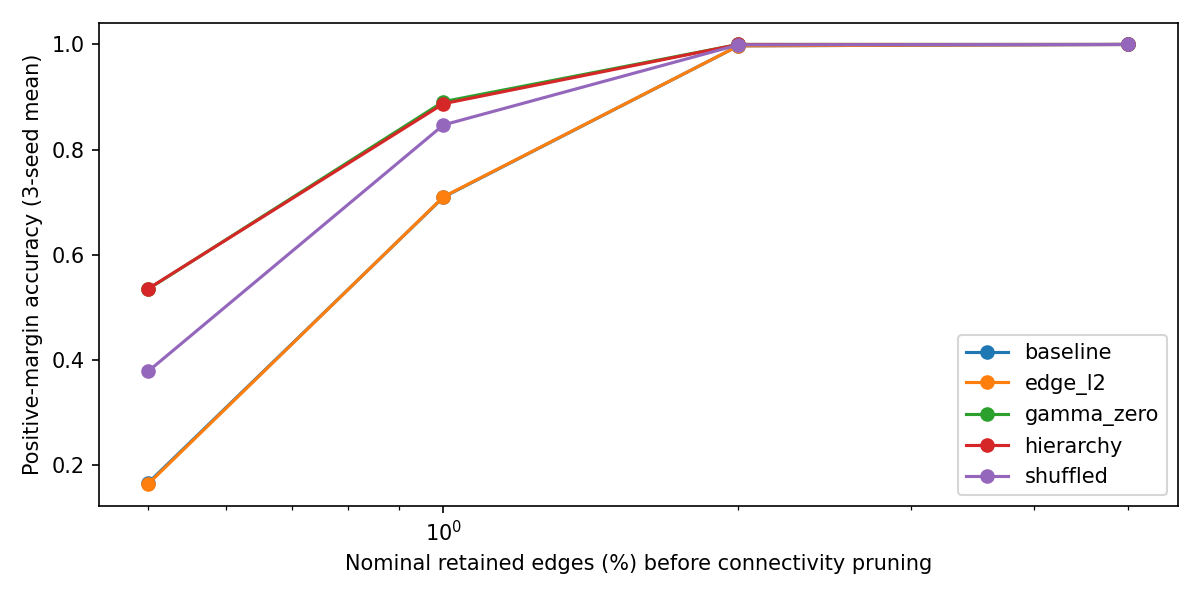

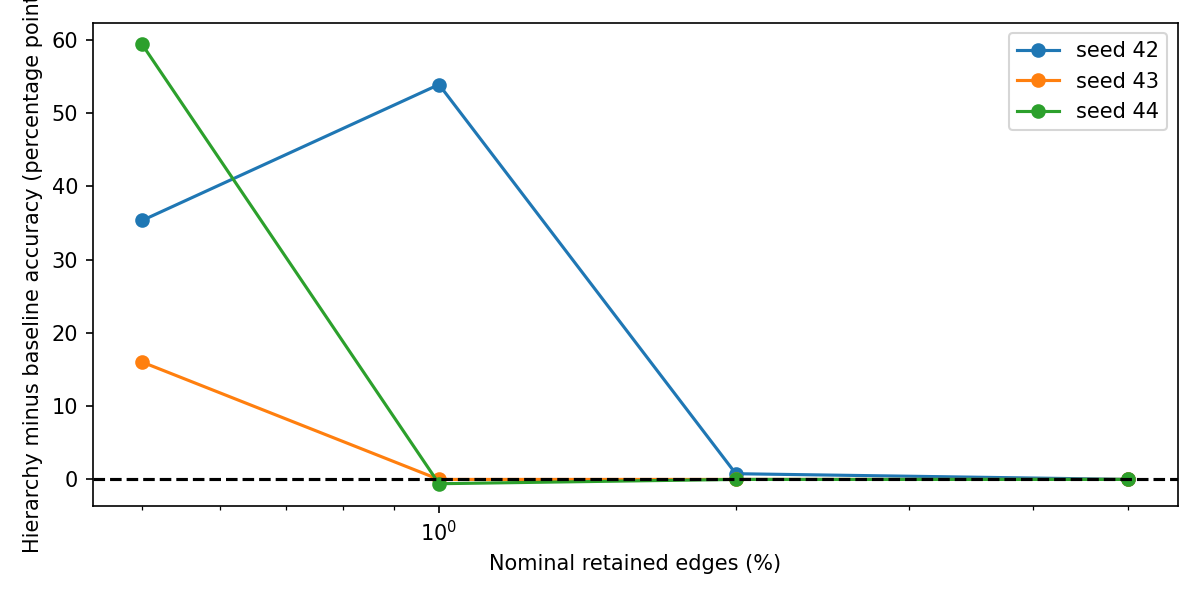

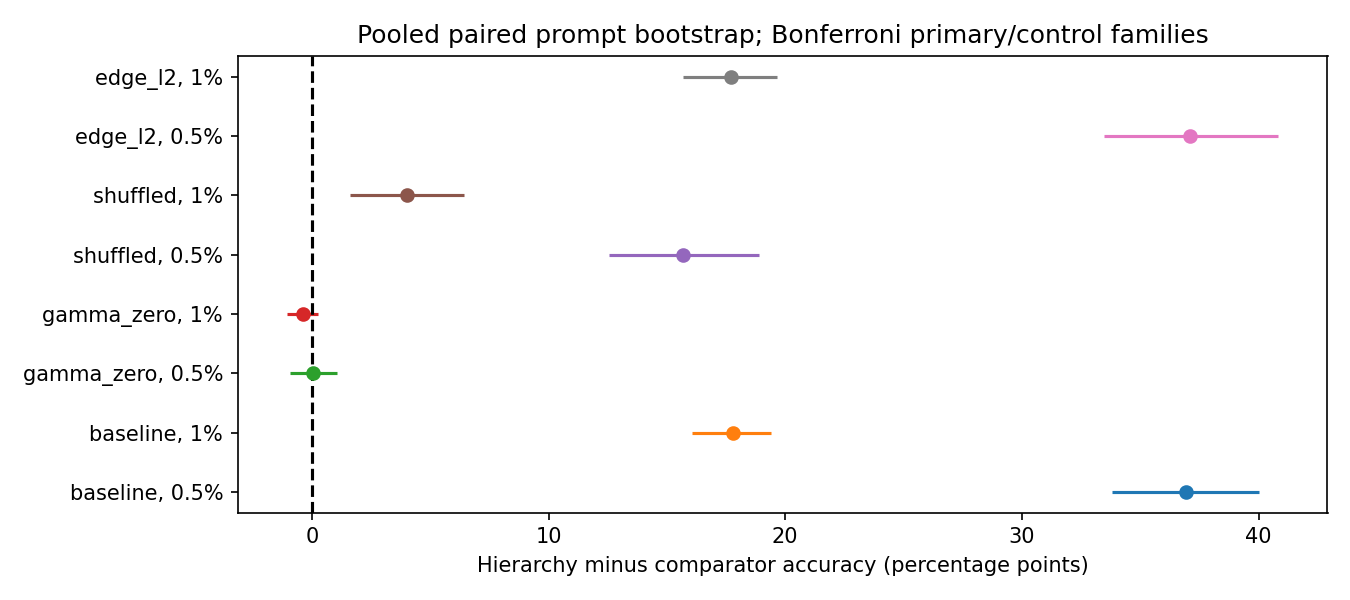

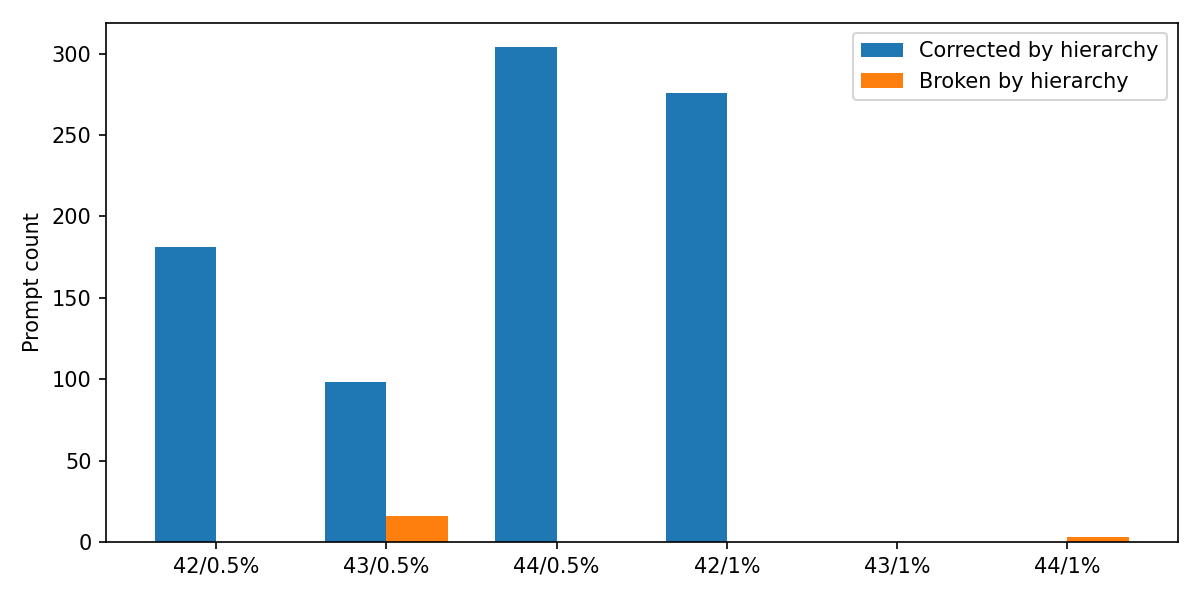

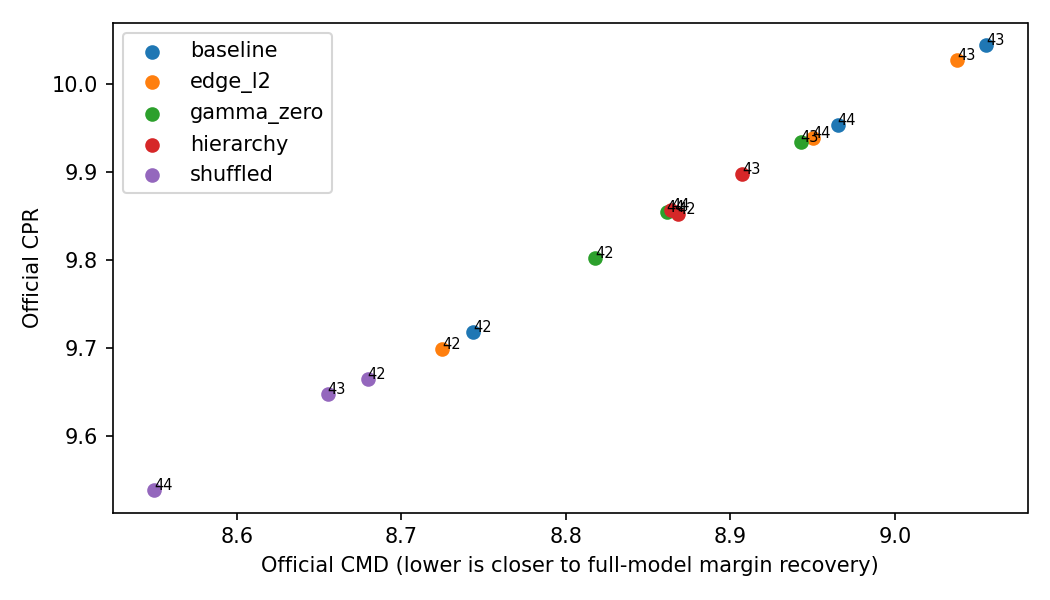

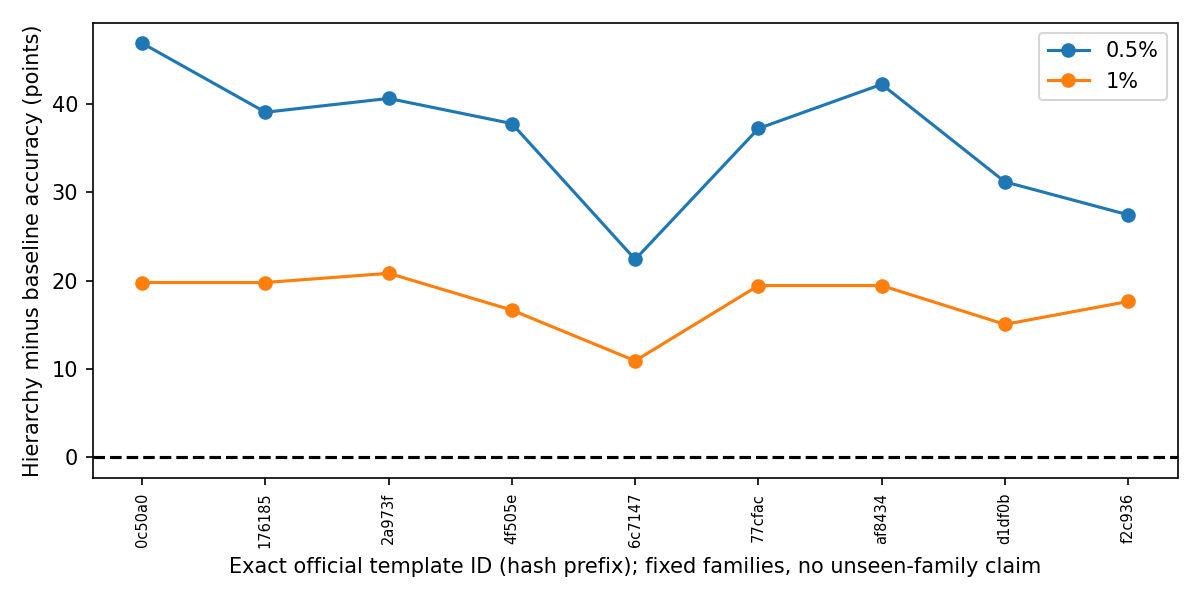

{'classification': 'Mixed or inconclusive',
 'primary_success': False,
 'structural_advantage': False,
 'primary_endpoint_results': [{'comparator': 'baseline',
   'seed': 'equal_seed_mean',
   'fraction': 0.005,
   'delta': 0.369140625,
   'lower': 0.337890625,
   'upper': 0.40007324218749984,
   'family_endpoints': 2,
   'corrected': 194.33333333333334,
   'broken': 5.333333333333333,
   'interval_scope': 'shared prompt draws; equally weighted FIXED seeds'},
  {'comparator': 'baseline',
   'seed': 'equal_seed_mean',
   'fraction': 0.01,
   'delta': 0.177734375,
   'lower': 0.1604736328125,
   'upper': 0.19401041666666669,
   'family_endpoints': 2,
   'corrected': 92.0,
   'broken': 1.0,
   'interval_scope': 'shared prompt draws; equally weighted FIXED seeds'}],
 'method_means': [{'method': 'baseline',
   'CPR': 9.904998041982218,
   'CMD': 8.921453591588305,
   'accuracy_log_AUC': 0.7108481964423846,
   'accuracy_0.005': 0.16666666666666666,
   'accuracy_0.01': 0.7096354166666666,
   

In [6]:
for name in ['compact_accuracy','per_seed_accuracy_difference','paired_bootstrap_intervals','corrected_vs_broken','cpr_vs_cmd','template_family_accuracy']:
    display(Image(filename=str(OUT/'figures'/(name+'.png'))))
display(json.loads((OUT/'research_summary.json').read_text()))


In [7]:
import re
report = (OUT/'GATE5D_COMPACT_GENERALIZATION_REPORT.md').read_text()
report = re.sub(r'^!\[.*?\]\(.*?\)\s*$', '', report, flags=re.MULTILINE)
display(Markdown(report))


# Gate 5D: Hierarchical MAttr compact-circuit generalization

## Interpretation of the completed experiment

The registered outcome is **mixed/inconclusive**, not a compact-generalization success under all frozen criteria. At **0.5% nominal retention**, mean positive-margin accuracy increased from **16.67% to 53.58%** (+36.91 percentage points; simultaneous95% interval **+33.79 to +40.01 points**), with positive changes in all three seeds. At **1%**, it increased from **70.96% to 88.74%** (+17.77 points; interval **+16.05 to +19.40**), but the changes were **+53.91, 0.00 and -0.59 points** for seeds42/43/44. Thus only one seed improved at1%, failing the prespecified at-least-two-seeds condition. The pooled bootstrap result does not override that condition. Baseline seeds43/44 were already at99.80%/100% at1%; this ceiling is context for the negative consistency decision, not a reason to relax it.

The gamma-zero hierarchy reached **53.52%/89.13%** at0.5%/1%, essentially matching or slightly exceeding the regularized hierarchy. This supports parameterization/optimization geometry as the main explanation rather than a demonstrated benefit from the residual penalty. The real hierarchy exceeded shuffled groups by **15.69 and4.04 points**, respectively, passing the prespecified pooled control comparisons with two-seed consistency. Generic edge regularization stayed near ordinary MAttr (**16.47%/71.03%**) and does not explain the large pooled compact gains; however, the real-versus-edge-L2 comparison also misses two-positive-seed consistency at1%. The complete structural-advantage criterion does not pass because all required control safeguards must pass.

Mean accuracy log-AUC rose **0.710848 to0.782791** (+0.071943; secondary95% paired prompt interval +0.067091 to+0.076649). Mean CPR fell **9.904998 to9.869015**, and mean CMD fell **8.921454 to8.879688**. There is no CPR or leaderboard improvement claim. Full-vocabulary top1, captured separately from the same logits, rose from12.17% to34.83% at0.5% and69.47% to78.26% at1%; these are not the positive-margin endpoints.

All nine exact official template strata had positive equally seed-weighted mean primary differences at both cutoffs. This is a descriptive result within existing template families, conditional on the seed mixture; it does not cure the1% seed inconsistency or establish unseen-template generalization. `official_template_labels.csv` maps each hash to its exact generic benchmark template, with no individual prompt text. Independent exclusion and optimizer-step audits supplement the frozen-protocol checks without changing the cohort, metrics or decisions.

The evidence supports a **narrow research motivation for very compact circuits, particularly the unregularized hierarchical parameterization**, rather than a validated regularization-specific improvement. Keep ordinary MAttr as the CPR reference and preserve the failed Gate5C/5D decisions. No further training, algorithm, ranking refinement, or leaderboard submission was performed.

## Executed decision

**Mixed or inconclusive**. All15 saved rankings were evaluated at exactly1000 training updates; Gate5D performs **zero optimizer updates and zero model backward calls**. This gate evaluates a new compact-accuracy hypothesis; it does not override Gate5C's failed CPR gate or authorize5000-step continuation. Ordinary MAttr remains the CPR reference unless independently demonstrated otherwise.

| fraction | delta | lower | upper | corrected | broken |
| --- | --- | --- | --- | --- | --- |
| 0.0050 | 0.3691 | 0.3379 | 0.4001 | 194.3333 | 5.3333 |
| 0.0100 | 0.1777 | 0.1605 | 0.1940 | 92.0000 | 1.0000 |

Differences are accuracy fractions, not percentage points. Pooled values equally weight the three FIXED trained seeds. Corrected/broken pooled counts are means of per-seed counts, not independent3N observations. The confidence intervals are paired, exact-template-stratified prompt bootstrap with5000 shared resamples, seed5642, Bonferroni over the two primary endpoints (97.5% marginal percentile intervals, simultaneous coverage at least95%). These intervals describe prompt sampling conditional on the fixed template mix, not training-seed significance or unseen-template performance.

## Protocol, historical exposure and cohort audit

Protocol SHA-256: `ec2bf0f0a2a4fd73f4699b3040e939ae64b629d46e715cf9e531dd92c4e1ad43`. Frozen before any model forward on the new cohort. All methods/seeds,15 checkpoint/effective-score hashes, original32491-edge mapping, exclusions, exact row IDs and UTF8 hashes, circuit grid, bootstrap and thresholds were recorded. Source pins, checkpoint metadata, group mappings, model configuration and effective exports were audited. No methods were selected or discarded using fresh-cohort performance.

Selected **512** official MIB IOI validation prompts from **9808** eligible unique strings, stratified proportionally across **9** exact official `template` values using largest-remainder quotas and seed5542. Exclusions use both filtered official row IDs and exact prompt SHA256, including prior small Gate2/3/4/5A development evaluations, Gate5B held-out confirmation, Gate5C development, and all located discovery-training manifests. Clean prompt duplicates are removed even if row IDs differ. Corrupted-prompt hashes from historical manifests are also excluded conservatively. Cohort audit records every input manifest/hash. Official names/labels are verified single tokens. No public/private test data or generated substitute is used.

**Historical Gate1 evaluated the full official10000-example validation split. These prompts are fresh relative to the smaller development/confirmation cohorts, not untouched by all previous research.** Template labels come directly from the dataset's `template` field; none are invented from text. Some templates can remain correlated, and stratified prompt intervals condition on the observed family mixture. This is not a held-out-family design.

## Frozen checkpoint provenance

All methods use Gate5C1000-step scores (baseline exact-bypass scores verified bitwise against Gate2). Effective scores are evaluated for hierarchical checkpoints; raw packed h/residual parameters are never interpreted as edge scores. Per-checkpoint hashes and config/cohort provenance are in the protocol and checkpoint_provenance.csv. No model training, score adaptation, ranking refinement or mask changes occurred.

## Official per-seed and descriptive means

| method | seed | CPR | CMD | accuracy_log_AUC | accuracy_0.005 | accuracy_0.01 | accuracy_0.02 | accuracy_0.05 | top1_0.005 | top1_0.01 | top1_0.02 | top1_0.05 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| baseline | 42 | 9.7178 | 8.7438 | 0.6359 | 0.0293 | 0.1309 | 0.9922 | 1.0000 | 0.0039 | 0.0859 | 0.9902 | 1.0000 |
| baseline | 43 | 10.0441 | 9.0553 | 0.7575 | 0.3164 | 0.9980 | 1.0000 | 1.0000 | 0.2695 | 0.9980 | 1.0000 | 1.0000 |
| baseline | 44 | 9.9531 | 8.9652 | 0.7391 | 0.1543 | 1.0000 | 1.0000 | 1.0000 | 0.0918 | 1.0000 | 1.0000 | 1.0000 |
| hierarchy | 42 | 9.8524 | 8.8679 | 0.7423 | 0.3828 | 0.6699 | 1.0000 | 1.0000 | 0.1953 | 0.4082 | 1.0000 | 1.0000 |
| hierarchy | 43 | 9.8978 | 8.9072 | 0.7818 | 0.4766 | 0.9980 | 1.0000 | 1.0000 | 0.3438 | 0.9980 | 1.0000 | 1.0000 |
| hierarchy | 44 | 9.8568 | 8.8640 | 0.8242 | 0.7480 | 0.9941 | 1.0000 | 1.0000 | 0.5059 | 0.9414 | 1.0000 | 1.0000 |
| gamma_zero | 42 | 9.8023 | 8.8179 | 0.7353 | 0.3906 | 0.6816 | 1.0000 | 1.0000 | 0.2051 | 0.4375 | 1.0000 | 1.0000 |
| gamma_zero | 43 | 9.9333 | 8.9428 | 0.7796 | 0.4668 | 0.9980 | 1.0000 | 1.0000 | 0.3359 | 0.9961 | 1.0000 | 1.0000 |
| gamma_zero | 44 | 9.8541 | 8.8612 | 0.8242 | 0.7480 | 0.9941 | 1.0000 | 1.0000 | 0.5059 | 0.9414 | 0.9980 | 1.0000 |
| shuffled | 42 | 9.6641 | 8.6796 | 0.7130 | 0.1816 | 0.6875 | 0.9980 | 1.0000 | 0.0762 | 0.5273 | 0.9961 | 1.0000 |
| shuffled | 43 | 9.6480 | 8.6552 | 0.8085 | 0.7559 | 0.9590 | 1.0000 | 1.0000 | 0.6562 | 0.8691 | 1.0000 | 1.0000 |
| shuffled | 44 | 9.5383 | 8.5497 | 0.7364 | 0.1992 | 0.8945 | 1.0000 | 1.0000 | 0.0820 | 0.8086 | 0.9902 | 1.0000 |
| edge_l2 | 42 | 9.6986 | 8.7246 | 0.6361 | 0.0293 | 0.1328 | 0.9922 | 1.0000 | 0.0039 | 0.0879 | 0.9902 | 1.0000 |
| edge_l2 | 43 | 10.0266 | 9.0379 | 0.7568 | 0.3105 | 0.9980 | 1.0000 | 1.0000 | 0.2637 | 0.9980 | 1.0000 | 1.0000 |
| edge_l2 | 44 | 9.9380 | 8.9501 | 0.7391 | 0.1543 | 1.0000 | 1.0000 | 1.0000 | 0.0918 | 1.0000 | 1.0000 | 1.0000 |

| method | CPR | CMD | accuracy_log_AUC | accuracy_0.005 | accuracy_0.01 | accuracy_0.02 | accuracy_0.05 | top1_0.005 | top1_0.01 | top1_0.02 | top1_0.05 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| baseline | 9.9050 | 8.9215 | 0.7108 | 0.1667 | 0.7096 | 0.9974 | 1.0000 | 0.1217 | 0.6947 | 0.9967 | 1.0000 |
| edge_l2 | 9.8877 | 8.9042 | 0.7107 | 0.1647 | 0.7103 | 0.9974 | 1.0000 | 0.1198 | 0.6953 | 0.9967 | 1.0000 |
| gamma_zero | 9.8632 | 8.8739 | 0.7797 | 0.5352 | 0.8913 | 1.0000 | 1.0000 | 0.3490 | 0.7917 | 0.9993 | 1.0000 |
| hierarchy | 9.8690 | 8.8797 | 0.7828 | 0.5358 | 0.8874 | 1.0000 | 1.0000 | 0.3483 | 0.7826 | 1.0000 | 1.0000 |
| shuffled | 9.6168 | 8.6282 | 0.7526 | 0.3789 | 0.8470 | 0.9993 | 1.0000 | 0.2715 | 0.7350 | 0.9954 | 1.0000 |

The original official signed `apply_topn(..., absolute=False, prune=True)` selects nominal circuit fractions. Rankings are nested before pruning; actual retained-edge counts can be smaller and are not forced to nominal counts. `faithfulness_curves.csv` and `compact_accuracy_and_edge_counts.csv` retain every official grid point and mask hash. Official CPR/CMD use ratios of cohort means and the unchanged evaluator's integrals; no homemade replacement is used. Accuracy is the proportion with correct-minus-incorrect margin>0. Full-vocabulary top1 is a separate official `acc` diagnostic captured from the same logits, with no extra model pass. CPR rewards amplification and is not interchangeable with model fidelity or compact accuracy; CMD is reported separately.

## Paired uncertainty, corrections and controls

| seed | fraction | delta | lower | upper | corrected | broken |
| --- | --- | --- | --- | --- | --- | --- |
| 42 | 0.0050 | 0.3535 | 0.3086 | 0.3984 | 181.0000 | 0.0000 |
| 43 | 0.0050 | 0.1602 | 0.1181 | 0.2031 | 98.0000 | 16.0000 |
| 44 | 0.0050 | 0.5938 | 0.5449 | 0.6426 | 304.0000 | 0.0000 |
| equal_seed_mean | 0.0050 | 0.3691 | 0.3379 | 0.4001 | 194.3333 | 5.3333 |
| 42 | 0.0100 | 0.5391 | 0.4883 | 0.5879 | 276.0000 | 0.0000 |
| 43 | 0.0100 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| 44 | 0.0100 | -0.0059 | -0.0137 | 0.0000 | 0.0000 | 3.0000 |
| equal_seed_mean | 0.0100 | 0.1777 | 0.1605 | 0.1940 | 92.0000 | 1.0000 |

| comparator | fraction | delta | lower | upper |
| --- | --- | --- | --- | --- |
| baseline | 0.0050 | 0.3691 | 0.3379 | 0.4001 |
| baseline | 0.0100 | 0.1777 | 0.1605 | 0.1940 |
| baseline | 0.0200 | 0.0026 | 0.0000 | 0.0059 |
| baseline | 0.0500 | 0.0000 | 0.0000 | 0.0000 |
| gamma_zero | 0.0050 | 0.0007 | -0.0091 | 0.0104 |
| gamma_zero | 0.0100 | -0.0039 | -0.0104 | 0.0026 |
| gamma_zero | 0.0200 | 0.0000 | 0.0000 | 0.0000 |
| gamma_zero | 0.0500 | 0.0000 | 0.0000 | 0.0000 |
| shuffled | 0.0050 | 0.1569 | 0.1255 | 0.1888 |
| shuffled | 0.0100 | 0.0404 | 0.0162 | 0.0645 |
| shuffled | 0.0200 | 0.0007 | 0.0000 | 0.0026 |
| shuffled | 0.0500 | 0.0000 | 0.0000 | 0.0000 |
| edge_l2 | 0.0050 | 0.3711 | 0.3345 | 0.4082 |
| edge_l2 | 0.0100 | 0.1771 | 0.1569 | 0.1967 |
| edge_l2 | 0.0200 | 0.0026 | 0.0000 | 0.0065 |
| edge_l2 | 0.0500 | 0.0000 | 0.0000 | 0.0000 |

| comparator | seed | delta | lower | upper |
| --- | --- | --- | --- | --- |
| baseline | 42 | 0.1064 | 0.0986 | 0.1144 |
| baseline | 43 | 0.0243 | 0.0198 | 0.0289 |
| baseline | 44 | 0.0851 | 0.0796 | 0.0905 |
| baseline | equal_seed_mean | 0.0719 | 0.0671 | 0.0766 |
| gamma_zero | 42 | 0.0070 | 0.0037 | 0.0105 |
| gamma_zero | 43 | 0.0023 | -0.0002 | 0.0050 |
| gamma_zero | 44 | 0.0000 | 0.0000 | 0.0000 |
| gamma_zero | equal_seed_mean | 0.0031 | 0.0016 | 0.0046 |
| shuffled | 42 | 0.0294 | 0.0234 | 0.0352 |
| shuffled | 43 | -0.0266 | -0.0322 | -0.0211 |
| shuffled | 44 | 0.0878 | 0.0828 | 0.0927 |
| shuffled | equal_seed_mean | 0.0302 | 0.0267 | 0.0337 |
| edge_l2 | 42 | 0.1062 | 0.0984 | 0.1142 |
| edge_l2 | 43 | 0.0250 | 0.0205 | 0.0296 |
| edge_l2 | 44 | 0.0851 | 0.0796 | 0.0905 |
| edge_l2 | equal_seed_mean | 0.0721 | 0.0672 | 0.0769 |

Primary success requires positive mean differences and positive corrected pooled lower bounds at both0.5%/1%, at least2/3 positive seeds at each, mean accuracy-log-AUC change>=-.02, no mean loss>.02 at2%/5%, and valid semantics. Per-seed primary intervals correct for two endpoints within each seed, not all six seed-specific tests. Control intervals use a distinct Bonferroni family of6 pooled contrasts (3controls x2 primary cutoffs). Accuracy-log-AUC95% intervals are secondary/unadjusted; bootstrap replicates use the linear functional of per-prompt correctness with weights verified against the official point estimate. No bootstrap treats seeds as independently sampled prompts.

Frozen decision details:

```json
{
  "primary": {
    "passed": false,
    "checks": {
      "valid_conventions": true,
      "positive_mean_0.005": true,
      "corrected_lower_0.005": true,
      "positive_2seeds_0.005": true,
      "positive_mean_0.01": true,
      "corrected_lower_0.01": true,
      "positive_2seeds_0.01": false,
      "accuracy_auc": true,
      "compact_2_5_safeguard": true
    }
  },
  "controls": {
    "gamma_zero": {
      "passed": false,
      "checks": {
        "valid_conventions": true,
        "positive_mean_0.005": true,
        "corrected_lower_0.005": false,
        "positive_2seeds_0.005": false,
        "positive_mean_0.01": false,
        "corrected_lower_0.01": false,
        "positive_2seeds_0.01": false
      }
    },
    "shuffled": {
      "passed": true,
      "checks": {
        "valid_conventions": true,
        "positive_mean_0.005": true,
        "corrected_lower_0.005": true,
        "positive_2seeds_0.005": true,
        "positive_mean_0.01": true,
        "corrected_lower_0.01": true,
        "positive_2seeds_0.01": true
      }
    },
    "edge_l2": {
      "passed": false,
      "checks": {
        "valid_conventions": true,
        "positive_mean_0.005": true,
        "corrected_lower_0.005": true,
        "positive_2seeds_0.005": true,
        "positive_mean_0.01": true,
        "corrected_lower_0.01": true,
        "positive_2seeds_0.01": false
      }
    }
  },
  "structural_advantage": false,
  "classification": "Mixed or inconclusive",
  "training_seed_significance_claim": false,
  "CPR_improvement_is_separate": true,
  "further_training_authorized": false
}
```

If gamma-zero hierarchy shows the same gain, evidence favors parameterization/optimization geometry rather than the residual penalty. Actual component grouping must beat shuffled grouping, gamma-zero hierarchy AND generic edge regularization at both primary cutoffs to support the registered structural claim. Group-score stability alone is not evidence of causal fidelity. Controls remain included regardless of outcome; no further sweep or training is authorized.

## Exact-template descriptive analysis

Full per-template/seed/method accuracy and top1 are in template_family_accuracy.csv; paired template contrasts are in template_family_paired_differences.csv. Template counts and IDs are frozen. Small per-template samples and repeated lexical patterns limit precision; the template plot is descriptive, with no post-hoc family selection or unseen-family significance claim.

## Actual retained edges

| method | seed | fraction | requested_edges | actual_edges | accuracy | top1_accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| baseline | 42 | 0.0050 | 162 | 92 | 0.0293 | 0.0039 |
| baseline | 42 | 0.0100 | 324 | 273 | 0.1309 | 0.0859 |
| baseline | 42 | 0.0200 | 649 | 638 | 0.9922 | 0.9902 |
| baseline | 42 | 0.0500 | 1624 | 1601 | 1.0000 | 1.0000 |
| baseline | 43 | 0.0050 | 162 | 118 | 0.3164 | 0.2695 |
| baseline | 43 | 0.0100 | 324 | 309 | 0.9980 | 0.9980 |
| baseline | 43 | 0.0200 | 649 | 638 | 1.0000 | 1.0000 |
| baseline | 43 | 0.0500 | 1624 | 1612 | 1.0000 | 1.0000 |
| baseline | 44 | 0.0050 | 162 | 116 | 0.1543 | 0.0918 |
| baseline | 44 | 0.0100 | 324 | 296 | 1.0000 | 1.0000 |
| baseline | 44 | 0.0200 | 649 | 636 | 1.0000 | 1.0000 |
| baseline | 44 | 0.0500 | 1624 | 1612 | 1.0000 | 1.0000 |
| hierarchy | 42 | 0.0050 | 162 | 114 | 0.3828 | 0.1953 |
| hierarchy | 42 | 0.0100 | 324 | 279 | 0.6699 | 0.4082 |
| hierarchy | 42 | 0.0200 | 649 | 631 | 1.0000 | 1.0000 |
| hierarchy | 42 | 0.0500 | 1624 | 1613 | 1.0000 | 1.0000 |
| hierarchy | 43 | 0.0050 | 162 | 129 | 0.4766 | 0.3438 |
| hierarchy | 43 | 0.0100 | 324 | 298 | 0.9980 | 0.9980 |
| hierarchy | 43 | 0.0200 | 649 | 635 | 1.0000 | 1.0000 |
| hierarchy | 43 | 0.0500 | 1624 | 1614 | 1.0000 | 1.0000 |
| hierarchy | 44 | 0.0050 | 162 | 118 | 0.7480 | 0.5059 |
| hierarchy | 44 | 0.0100 | 324 | 290 | 0.9941 | 0.9414 |
| hierarchy | 44 | 0.0200 | 649 | 639 | 1.0000 | 1.0000 |
| hierarchy | 44 | 0.0500 | 1624 | 1609 | 1.0000 | 1.0000 |
| gamma_zero | 42 | 0.0050 | 162 | 114 | 0.3906 | 0.2051 |
| gamma_zero | 42 | 0.0100 | 324 | 285 | 0.6816 | 0.4375 |
| gamma_zero | 42 | 0.0200 | 649 | 628 | 1.0000 | 1.0000 |
| gamma_zero | 42 | 0.0500 | 1624 | 1614 | 1.0000 | 1.0000 |
| gamma_zero | 43 | 0.0050 | 162 | 121 | 0.4668 | 0.3359 |
| gamma_zero | 43 | 0.0100 | 324 | 295 | 0.9980 | 0.9961 |
| gamma_zero | 43 | 0.0200 | 649 | 637 | 1.0000 | 1.0000 |
| gamma_zero | 43 | 0.0500 | 1624 | 1616 | 1.0000 | 1.0000 |
| gamma_zero | 44 | 0.0050 | 162 | 119 | 0.7480 | 0.5059 |
| gamma_zero | 44 | 0.0100 | 324 | 291 | 0.9941 | 0.9414 |
| gamma_zero | 44 | 0.0200 | 649 | 639 | 1.0000 | 0.9980 |
| gamma_zero | 44 | 0.0500 | 1624 | 1607 | 1.0000 | 1.0000 |
| shuffled | 42 | 0.0050 | 162 | 123 | 0.1816 | 0.0762 |
| shuffled | 42 | 0.0100 | 324 | 309 | 0.6875 | 0.5273 |
| shuffled | 42 | 0.0200 | 649 | 643 | 0.9980 | 0.9961 |
| shuffled | 42 | 0.0500 | 1624 | 1586 | 1.0000 | 1.0000 |
| shuffled | 43 | 0.0050 | 162 | 140 | 0.7559 | 0.6562 |
| shuffled | 43 | 0.0100 | 324 | 304 | 0.9590 | 0.8691 |
| shuffled | 43 | 0.0200 | 649 | 623 | 1.0000 | 1.0000 |
| shuffled | 43 | 0.0500 | 1624 | 1611 | 1.0000 | 1.0000 |
| shuffled | 44 | 0.0050 | 162 | 111 | 0.1992 | 0.0820 |
| shuffled | 44 | 0.0100 | 324 | 304 | 0.8945 | 0.8086 |
| shuffled | 44 | 0.0200 | 649 | 635 | 1.0000 | 0.9902 |
| shuffled | 44 | 0.0500 | 1624 | 1618 | 1.0000 | 1.0000 |
| edge_l2 | 42 | 0.0050 | 162 | 93 | 0.0293 | 0.0039 |
| edge_l2 | 42 | 0.0100 | 324 | 274 | 0.1328 | 0.0879 |
| edge_l2 | 42 | 0.0200 | 649 | 638 | 0.9922 | 0.9902 |
| edge_l2 | 42 | 0.0500 | 1624 | 1604 | 1.0000 | 1.0000 |
| edge_l2 | 43 | 0.0050 | 162 | 116 | 0.3105 | 0.2637 |
| edge_l2 | 43 | 0.0100 | 324 | 310 | 0.9980 | 0.9980 |
| edge_l2 | 43 | 0.0200 | 649 | 640 | 1.0000 | 1.0000 |
| edge_l2 | 43 | 0.0500 | 1624 | 1616 | 1.0000 | 1.0000 |
| edge_l2 | 44 | 0.0050 | 162 | 115 | 0.1543 | 0.0918 |
| edge_l2 | 44 | 0.0100 | 324 | 305 | 1.0000 | 1.0000 |
| edge_l2 | 44 | 0.0200 | 649 | 636 | 1.0000 | 1.0000 |
| edge_l2 | 44 | 0.0500 | 1624 | 1612 | 1.0000 | 1.0000 |

## Computation and inference correctness

Official full-grid evaluation wall time **22.330minutes**. Inference-process wall time including loading/correctness **22.749minutes**. Actual model forward calls **7,950**, individual example-forwards **155,720**. Unique evaluation prompts **512**, reused identically for each of15 rankings. CUDA timers synchronize and use monotonic perf_counter; root-forward counters count real calls, not cache hits. Official graph-independent reference scalar/result cache hits **28**; donor activation cache disabled, no mutable patched activations reused. References computed once for the same model/cohort/intervention are safe to share across rankings.

Peak allocated CUDA **2384.65MiB**, peak reserved **8796.00MiB**, sampled peak CPU RSS **2884.03MiB**. These are allocator/RSS measurements, not total physical VRAM occupancy or CUDA kernel utilization time. Per-method timing and forwards are in per_method_compute.csv; the first method bears one-time reference computation. All methods use batch20; no silent resource adaptation. Model parameters have no stored gradients and complete before/after weight hashes match. Correctness checks compare repeated and singleton batching, full-circuit versus clean reference, nested/pruned masks, and official reference-cache equivalence before the full evaluation.

| method_seed | seconds | forward_batches | example_forwards | peak_allocated_mib | peak_reserved_mib | sampled_peak_cpu_rss_mib |
| --- | --- | --- | --- | --- | --- | --- |
| baseline_s42 | 103.3860 | 624 | 12288 | 2384.6470 | 8796.0000 | 1698.7031 |
| baseline_s43 | 87.0790 | 520 | 10240 | 2384.6470 | 8796.0000 | 1696.8477 |
| baseline_s44 | 88.0017 | 520 | 10240 | 2384.6470 | 8796.0000 | 1696.9375 |
| hierarchy_s42 | 87.6462 | 520 | 10240 | 2384.6470 | 8796.0000 | 1697.0703 |
| hierarchy_s43 | 88.0407 | 520 | 10240 | 2384.6470 | 8796.0000 | 1697.2109 |
| hierarchy_s44 | 88.2559 | 520 | 10240 | 2384.6470 | 8796.0000 | 1697.3359 |
| gamma_zero_s42 | 88.4307 | 520 | 10240 | 2384.6470 | 8796.0000 | 1694.7305 |
| gamma_zero_s43 | 87.4828 | 520 | 10240 | 2384.6470 | 8796.0000 | 1695.0117 |
| gamma_zero_s44 | 88.3476 | 520 | 10240 | 2384.6470 | 8796.0000 | 1695.0898 |
| shuffled_s42 | 88.2577 | 520 | 10240 | 2384.6470 | 8796.0000 | 1695.1289 |
| shuffled_s43 | 88.3856 | 520 | 10240 | 2384.6470 | 8796.0000 | 1695.1328 |
| shuffled_s44 | 88.7464 | 520 | 10240 | 2384.6470 | 8796.0000 | 1695.1367 |
| edge_l2_s42 | 87.5824 | 520 | 10240 | 2384.6470 | 8796.0000 | 1695.2188 |
| edge_l2_s43 | 87.2518 | 520 | 10240 | 2384.6470 | 8796.0000 | 1695.2500 |
| edge_l2_s44 | 92.9190 | 520 | 10240 | 2384.6470 | 8796.0000 | 1695.3320 |

## Recommendation and limitations

Use the frozen primary/control decisions above to interpret compact-accuracy generalization separately from structural attribution and CPR. A primary success warrants further independent-cohort research as a recommendation only; it does not demonstrate a leaderboard victory. A gamma-zero tie prevents attributing gains to regularization. Only three fixed paired training/subset seeds were measured, the official templates are reused, historical full-validation exposure remains, and no full-data/multi-model generalization was tested. Preserve the original MAttr and historical failed gates. Stop after Gate5D; no new training, algorithms, further gates or leaderboard submission.








## Final preservation audit

```json
{
  "passed": true,
  "historical_files_unchanged": 7724,
  "evaluated_rankings": 15,
  "protocol_sha256": "ec2bf0f0a2a4fd73f4699b3040e939ae64b629d46e715cf9e531dd92c4e1ad43",
  "cohort_size": 512,
  "actual_forwards_verified": true,
  "weight_updates": 0,
  "model_backwards": 0,
  "frozen_sources_and_checkpoints_verified": true,
  "additional_model_forwards": 0
}
```
